![Python Banner](../../Image/05_02_meta_learners.png)


# 2.1 Meta-Learner with Binary Treatments


## Overview

Meta-learners are flexible, modular frameworks designed to estimate the Conditional Average Treatment Effect (CATE) by decomposing the causal estimation problem into one or more supervised learning sub-problems. Rather than requiring a purpose-built causal model, meta-learners treat any regression or classification algorithm — such as random forests, gradient boosting machines, LASSO, or neural networks — as a plug-in "base learner," making them highly adaptable to a wide range of data settings. This separation of concerns between the causal structure and the predictive machinery is one of the defining advantages of the meta-learning approach.

For binary treatments, where $W_i \in \{0, 1\}$ indicates whether unit $i$ received the treatment, the central challenge is to recover individual-level treatment effect heterogeneity from observed outcomes. The key idea across all binary-treatment meta-learners is to leverage the treatment indicator in structurally different ways — either by fitting separate outcome models for each treatment arm, by modeling the treatment propensity directly, or by constructing pseudo-outcomes that isolate the treatment effect signal. These design choices lead to a family of estimators that differ substantially in their assumptions, bias-variance tradeoffs, and sensitivity to model misspecification.

Binary treatment meta-learners are particularly consequential in **observational studies**, where treatment assignment is not randomized and is instead driven by observed (and potentially unobserved) covariates. In such settings, naive comparisons between treated and control units conflate the treatment effect with confounding — systematic differences in baseline characteristics between the two groups. Meta-learners address confounding through **unconfoundedness** (or ignorability) assumptions, combined with careful modeling of the outcome and/or treatment assignment process. The quality of CATE estimates therefore depends critically on the richness of the observed covariate set and the adequacy of the base learner in capturing the relevant data structure.

The most widely studied meta-learners for binary treatments include:

-   **The S-Learner** (Single learner), which fits a single outcome model including the treatment indicator as a feature, and recovers the CATE as the difference in predicted outcomes under $W = 1$ versus $W = 0$. Its simplicity makes it computationally attractive, but it can suffer from regularization bias if the base learner shrinks the treatment indicator coefficient toward zero.

-   **The T-Learner** (Two-model learner), which fits separate outcome models for the treated and control groups and estimates the CATE as their difference. This approach naturally allows treatment effect heterogeneity but can exhibit high variance when the two groups are imbalanced in size or covariate distribution.

-   **The X-Learner**, which extends the T-Learner by constructing imputed treatment effects for each unit using the other group's fitted model, and then combining these estimates via a weighting function, often based on the propensity score. The X-Learner is especially effective in settings with significant imbalance between treatment and control group sizes.

-   **The R-Learner** (Robinson decomposition learner), which builds on the partial linear residualization idea of Robinson (1988) to orthogonalize both the outcome and the treatment before fitting the CATE. It is designed to target the CATE directly, and enjoys favorable theoretical properties under cross-fitting, connecting closely to the double/debiased machine learning literature.

-   **The DR-Learner** (Doubly Robust learner), which leverages augmented inverse probability weighting (AIPW) to construct doubly robust pseudo-outcomes. An estimator is doubly robust in the sense that it remains consistent if *either* the outcome model *or* the propensity score model is correctly specified — though not necessarily both.

Each meta-learner embodies a different set of implicit assumptions and practical tradeoffs. Their performance is highly sensitive to characteristics of the data, including: (i) the **degree of treatment group imbalance**, which can destabilize estimators that rely heavily on extrapolation across groups; (ii) the **smoothness and complexity of the underlying CATE function**, which determines how well the base learner can approximate it; (iii) the **signal-to-noise ratio** in the outcome, which affects variance of effect estimates; and (iv) the **overlap** in covariate distributions between treated and control units, which is a prerequisite for identification in observational settings. Understanding these sensitivities is essential for selecting an appropriate meta-learner in practice, and motivates the use of simulation studies and cross-validated evaluation strategies.


## Implementation in Python

In this notebook, we will generate some synthetic data to demonstrate how to use the various Meta-Learner algorithms with `PyCausalML` in order to estimate Individual Treatment Effects and Average Treatment Effects with confidence intervals. We will also validate the meta-learners' performance using the same synthetic data generation, comparing three base regressors: **Linear Regression** (`lm`), **Random Forest** (random forests (`learner="rf"`)), and **XGBoost** (XGBoost (`learner="xgb"`)), across S-, T-, X-, and R-learners. We will run **k** simulations (3 when `CAUSALML_FAST_RENDER=TRUE`, 10 otherwise) with train/validation split and report **Abs % Error of ATE**, **MSE**, and **KL Divergence** (like the [Python CausalML example](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data.html)).


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")


PyCausalML ready.


## Part A: Example Workflow using Synthetic Data

### Generate synthetic data

We have implemented 4 modes of generating synthetic data (specified by input parameter `mode`). Refer to the References section for more detail on these data generation processes.


In [2]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")

def ate_row(name, model, X):
    cate = np.asarray(model.predict(X), dtype=float)
    info = model.average_treatment_effect(X)
    est = float(info["estimate"])
    se = float(info["std.err"])
    if not np.isfinite(se):
        se = float(np.std(cate, ddof=1) / np.sqrt(len(cate)))
        est = float(np.mean(cate))
    return {
        "learner": name,
        "ate": est,
        "se": se,
        "ci_lower": est - 1.96 * se,
        "ci_upper": est + 1.96 * se,
    }

def abs_pct_ate(pred, truth):
    denom = abs(float(np.mean(truth)))
    if denom < 1e-8:
        return np.nan
    return 100.0 * abs(float(np.mean(pred) - np.mean(truth))) / denom

def kl_divergence(pred, truth, bins=15):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    lo = float(min(pred.min(), truth.min()))
    hi = float(max(pred.max(), truth.max()))
    if not np.isfinite(lo) or hi <= lo:
        return np.nan
    hp, _ = np.histogram(pred, bins=bins, range=(lo, hi))
    hq, _ = np.histogram(truth, bins=bins, range=(lo, hi))
    hp = hp.astype(float) + 1e-3
    hq = hq.astype(float) + 1e-3
    hp /= hp.sum()
    hq /= hq.sum()
    return float(np.sum(hp * np.log(hp / hq)))

def cumulative_gain(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w)[order]
    n = len(y)
    frac = np.arange(1, n + 1) / n
    gain = np.empty(n)
    for i in range(n):
        ww = w[: i + 1]
        yy = y[: i + 1]
        n1 = int((ww == 1).sum())
        n0 = int((ww == 0).sum())
        gain[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[ww == 1].mean() - yy[ww == 0].mean()) * (i + 1) / n
    return frac, gain

def tutorial_file(name: str) -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("Tutorials") / "05_02_Meta_Learners" / "data" / name,
            Path("data") / name,
        ):
            path = cand / rel
            if path.is_file():
                return path
    raise FileNotFoundError(name)

rng = np.random.default_rng(42)
dat = synthetic_data(mode=2, n=1200, p=10, sigma=1.0, random_state=42)
X = dat["X"]
y = dat["y"]
w = dat["w"]
tau = dat["tau"]
feature_names = [f"X{i+1}" for i in range(X.shape[1])]
print(X.shape, "treatment rate", round(float(w.mean()), 3), "true ATE", round(float(tau.mean()), 3))


Imported PyCausalML
(1200, 10) treatment rate 0.516 true ATE 0.53


### Calculate Average Treatment Effect (ATE)

A meta-learner can be instantiated by providing a base regressor: **Linear Regression** (`lm`), **Random Forest** (`learner="rf"`), or **XGBoost** (`xgb`). Random forests and XGBoost are the `rf` and `xgb` base learners.

#### S-Learner (Linear Regression, Random Forest, XGBoost)


#### T-Learner (Linear Regression, Random Forest, XGBoost)


#### X-Learner with propensity score input


#### X-Learner without propensity score input


#### R-Learner with and without propensity score input


In [3]:
bases = {"Linear regression": "lm", "Random forest": "rf", "XGBoost": "xgb"}
families = {
    "S-Learner": SLearner,
    "T-Learner": TLearner,
    "X-Learner": XLearner,
    "R-Learner": RLearner,
}
fitted = {}
rows = []
for family, cls in families.items():
    for base_name, base in bases.items():
        model = cls(learner=base, n_estimators=N_EST, random_state=42)
        model.fit(X, w, y, feature_names=feature_names)
        key = f"{family} ({base_name})"
        fitted[key] = model
        row = ate_row(key, model, X)
        row["true_ate"] = float(tau.mean())
        rows.append(row)
ate_table = pd.DataFrame(rows)
print(ate_table.round(3).to_string(index=False))
print("PyCausalML estimates the propensity score inside the X-Learner and the R-Learner.")


                      learner   ate    se  ci_lower  ci_upper  true_ate
S-Learner (Linear regression) 0.580 0.000     0.580     0.580      0.53
    S-Learner (Random forest) 0.486 0.024     0.438     0.533      0.53
          S-Learner (XGBoost) 0.293 0.007     0.280     0.306      0.53
T-Learner (Linear regression) 0.585 0.021     0.544     0.625      0.53
    T-Learner (Random forest) 0.579 0.031     0.519     0.640      0.53
          T-Learner (XGBoost) 0.578 0.024     0.531     0.625      0.53
X-Learner (Linear regression) 0.585 0.021     0.544     0.625      0.53
    X-Learner (Random forest) 0.569 0.028     0.513     0.624      0.53
          X-Learner (XGBoost) 0.583 0.021     0.543     0.623      0.53
R-Learner (Linear regression) 0.538 0.085     0.372     0.705      0.53
    R-Learner (Random forest) 0.645 0.084     0.482     0.809      0.53
          R-Learner (XGBoost) 0.632 0.083     0.469     0.795      0.53
PyCausalML estimates the propensity score inside the X-Learner a

### Calculate Individual Treatment Effect (ITE/CATE)

CATE stands for Conditional Average Treatment Effect.


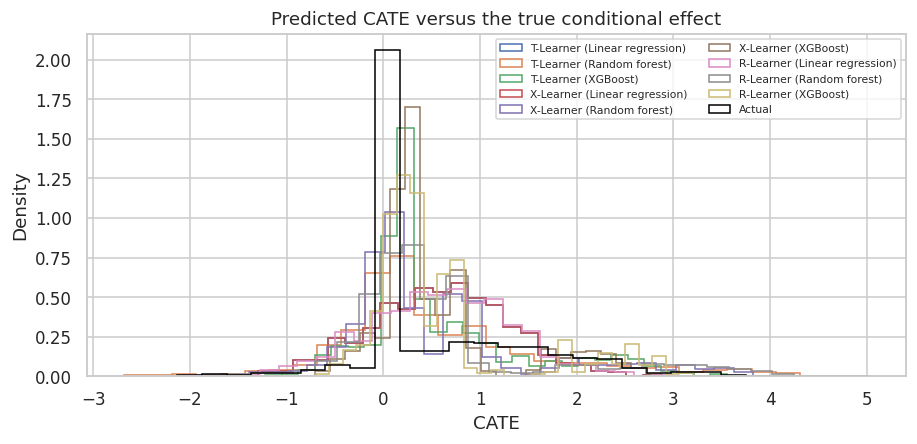

In [4]:
cate = {name: np.asarray(model.predict(X), dtype=float) for name, model in fitted.items()}
show = [k for k in cate if k.startswith(("T-Learner", "X-Learner", "R-Learner"))]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for name in show:
    ax.hist(cate[name], bins=28, histtype="step", density=True, lw=1.4, label=name)
ax.hist(tau, bins=28, histtype="step", density=True, color="black", lw=2, label="Actual")
ax.set_xlabel("CATE")
ax.set_ylabel("Density")
ax.set_title("Predicted CATE versus the true conditional effect")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()


## Part B: Validating Meta-Learner Accuracy

We validate the meta-learners' performance using the same synthetic data generation as in Part A (`simulate_nuisance_and_easy_treatment`). We compare three base regressors: **Linear Regression** (`lm`), **Random Forest** (random forests (`learner="rf"`)), and **XGBoost** (XGBoost (`learner="xgb"`)), across S-, T-, X-, and R-learners. We run **k** simulations (3 when `CAUSALML_FAST_RENDER=TRUE`, 10 otherwise) with train/validation split and report **Abs % Error of ATE**, **MSE**, and **KL Divergence** (like the [Python CausalML example](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data.html)).

### Holdout summary (k runs; reduced when fast_run)


In [5]:
def ate_row(name, model, X):
    cate = np.asarray(model.predict(X), dtype=float)
    info = model.average_treatment_effect(X)
    est = float(info["estimate"])
    se = float(info["std.err"])
    if not np.isfinite(se):
        se = float(np.std(cate, ddof=1) / np.sqrt(len(cate)))
        est = float(np.mean(cate))
    return {
        "learner": name,
        "ate": est,
        "se": se,
        "ci_lower": est - 1.96 * se,
        "ci_upper": est + 1.96 * se,
    }

def abs_pct_ate(pred, truth):
    denom = abs(float(np.mean(truth)))
    if denom < 1e-8:
        return np.nan
    return 100.0 * abs(float(np.mean(pred) - np.mean(truth))) / denom

def kl_divergence(pred, truth, bins=15):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    lo = float(min(pred.min(), truth.min()))
    hi = float(max(pred.max(), truth.max()))
    if not np.isfinite(lo) or hi <= lo:
        return np.nan
    hp, _ = np.histogram(pred, bins=bins, range=(lo, hi))
    hq, _ = np.histogram(truth, bins=bins, range=(lo, hi))
    hp = hp.astype(float) + 1e-3
    hq = hq.astype(float) + 1e-3
    hp /= hp.sum()
    hq /= hq.sum()
    return float(np.sum(hp * np.log(hp / hq)))

def cumulative_gain(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w)[order]
    n = len(y)
    frac = np.arange(1, n + 1) / n
    gain = np.empty(n)
    for i in range(n):
        ww = w[: i + 1]
        yy = y[: i + 1]
        n1 = int((ww == 1).sum())
        n0 = int((ww == 0).sum())
        gain[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[ww == 1].mean() - yy[ww == 0].mean()) * (i + 1) / n
    return frac, gain

def tutorial_file(name: str) -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("Tutorials") / "05_02_Meta_Learners" / "data" / name,
            Path("data") / name,
        ):
            path = cand / rel
            if path.is_file():
                return path
    raise FileNotFoundError(name)

k_sims = 3
records = []
for sim in range(k_sims):
    draw = synthetic_data(mode=2, n=900, p=8, sigma=1.0, random_state=100 + sim)
    Xs, ys, ws, taus = draw["X"], draw["y"], draw["w"], draw["tau"]
    names = [f"X{i+1}" for i in range(Xs.shape[1])]
    rng = np.random.default_rng(sim)
    hold = rng.choice(len(ys), size=round(0.2 * len(ys)), replace=False)
    train = np.setdiff1d(np.arange(len(ys)), hold)
    for family, cls in families.items():
        for base_name, base in bases.items():
            model = cls(learner=base, n_estimators=N_EST, random_state=sim)
            model.fit(Xs[train], ws[train], ys[train], feature_names=names)
            for split, idx in (("train", train), ("validation", hold)):
                pred = model.predict(Xs[idx])
                records.append({
                    "learner": f"{family} ({base_name})",
                    "split": split,
                    "abs_pct_ate": abs_pct_ate(pred, taus[idx]),
                    "mse": float(np.mean((pred - taus[idx]) ** 2)),
                    "kl": kl_divergence(pred, taus[idx]),
                })
valid_df = pd.DataFrame(records)
summary = (
    valid_df.groupby(["learner", "split"], as_index=False)[["abs_pct_ate", "mse", "kl"]]
    .mean()
)
train_summary = summary[summary["split"] == "train"].drop(columns="split")
validation_summary = summary[summary["split"] == "validation"].drop(columns="split")
print("Train summary")
print(train_summary.round(3).to_string(index=False))
print("\nValidation summary")
print(validation_summary.round(3).to_string(index=False))


Train summary
                      learner  abs_pct_ate   mse    kl
R-Learner (Linear regression)       13.015 0.391 0.559
    R-Learner (Random forest)       14.692 0.221 0.434
          R-Learner (XGBoost)       13.218 0.189 0.350
S-Learner (Linear regression)       12.709 0.758 2.842
    S-Learner (Random forest)       24.749 0.197 0.177
          S-Learner (XGBoost)       49.844 0.613 0.998
T-Learner (Linear regression)       13.222 0.380 0.584
    T-Learner (Random forest)        9.977 0.186 0.351
          T-Learner (XGBoost)       10.678 0.176 0.311
X-Learner (Linear regression)       13.222 0.380 0.584
    X-Learner (Random forest)        8.267 0.094 0.388
          X-Learner (XGBoost)       12.437 0.145 0.430

Validation summary
                      learner  abs_pct_ate   mse    kl
R-Learner (Linear regression)       19.140 0.414 0.564
    R-Learner (Random forest)       16.794 0.198 0.527
          R-Learner (XGBoost)       15.992 0.211 0.710
S-Learner (Linear regression)  

### Train summary table


### Validation summary table


### Scatter plot: Train vs Validation (like scatter_plot_summary_holdout)


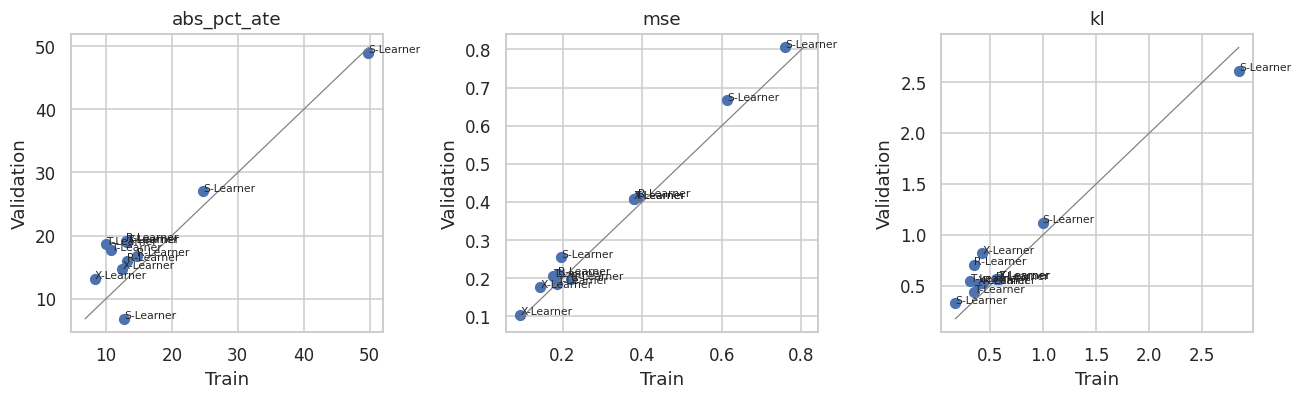

In [6]:
merged = train_summary.merge(validation_summary, on="learner", suffixes=("_train", "_valid"))
metrics = ["abs_pct_ate", "mse", "kl"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, metric in zip(axes, metrics):
    ax.scatter(merged[f"{metric}_train"], merged[f"{metric}_valid"], s=40)
    for _, row in merged.iterrows():
        ax.annotate(row["learner"].split()[0], (row[f"{metric}_train"], row[f"{metric}_valid"]), fontsize=7)
    lims = [
        min(merged[f"{metric}_train"].min(), merged[f"{metric}_valid"].min()),
        max(merged[f"{metric}_train"].max(), merged[f"{metric}_valid"].max()),
    ]
    ax.plot(lims, lims, color="grey", lw=0.8)
    ax.set_xlabel("Train")
    ax.set_ylabel("Validation")
    ax.set_title(metric)
fig.tight_layout()
plt.show()


### Bar plots (like bar_plot_summary_holdout; optionally drop S Learner LR for readability)


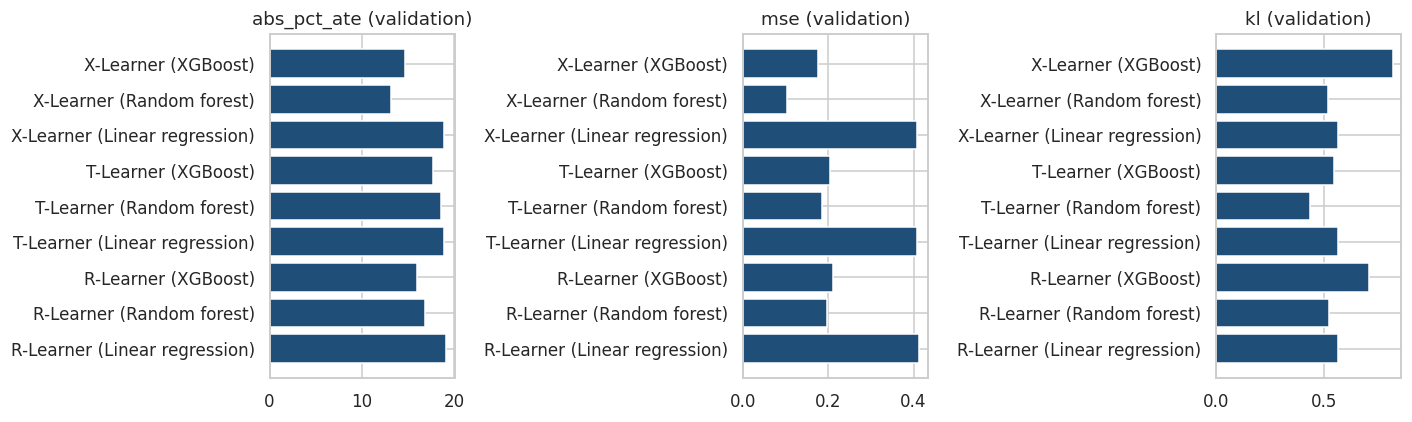

In [7]:
plot_df = validation_summary[~validation_summary["learner"].str.startswith("S-Learner")].copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["abs_pct_ate", "mse", "kl"]):
    ax.barh(plot_df["learner"], plot_df[metric], color="#1F4E79")
    ax.set_title(metric + " (validation)")
fig.tight_layout()
plt.show()


### Single simulation: train and validation predictions

Mirror Python `get_synthetic_preds_holdout(simulate_nuisance_and_easy_treatment, n=50000, valid_size=0.2)`.


In [8]:
draw = synthetic_data(mode=2, n=1000, p=8, sigma=1.0, random_state=7)
rng = np.random.default_rng(7)
hold = rng.choice(len(draw["y"]), size=200, replace=False)
train = np.setdiff1d(np.arange(len(draw["y"])), hold)
names = [f"X{i+1}" for i in range(draw["X"].shape[1])]
single = {}
for family, cls in (("T-Learner", TLearner), ("X-Learner", XLearner), ("R-Learner", RLearner)):
    model = cls(learner="xgb", n_estimators=N_EST, random_state=7)
    model.fit(draw["X"][train], draw["w"][train], draw["y"][train], feature_names=names)
    single[family] = {
        "train": model.predict(draw["X"][train]),
        "valid": model.predict(draw["X"][hold]),
        "tau_train": draw["tau"][train],
        "tau_valid": draw["tau"][hold],
        "model": model,
        "X_train": draw["X"][train],
        "y_train": draw["y"][train],
        "w_train": draw["w"][train],
        "names": names,
    }
print("Single simulation fitted:", list(single))


Single simulation fitted: ['T-Learner', 'X-Learner', 'R-Learner']


### Distribution plot for single simulation (like distr_plot_single_sim)


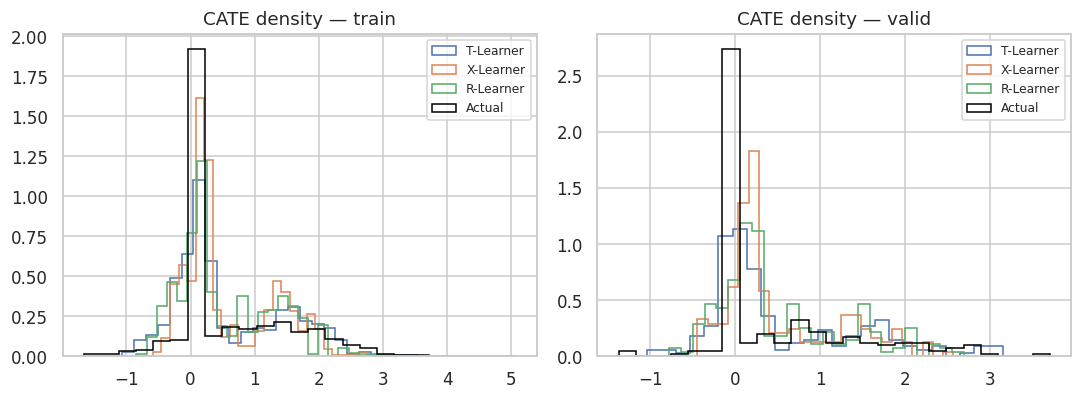

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, split, truth_key in ((axes[0], "train", "tau_train"), (axes[1], "valid", "tau_valid")):
    for family, payload in single.items():
        ax.hist(payload[split], bins=25, histtype="step", density=True, label=family)
    ax.hist(single["T-Learner"][truth_key], bins=25, histtype="step", density=True, color="black", label="Actual")
    ax.set_title(f"CATE density — {split}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Scatter plots: predicted CATE vs actual (single simulation)


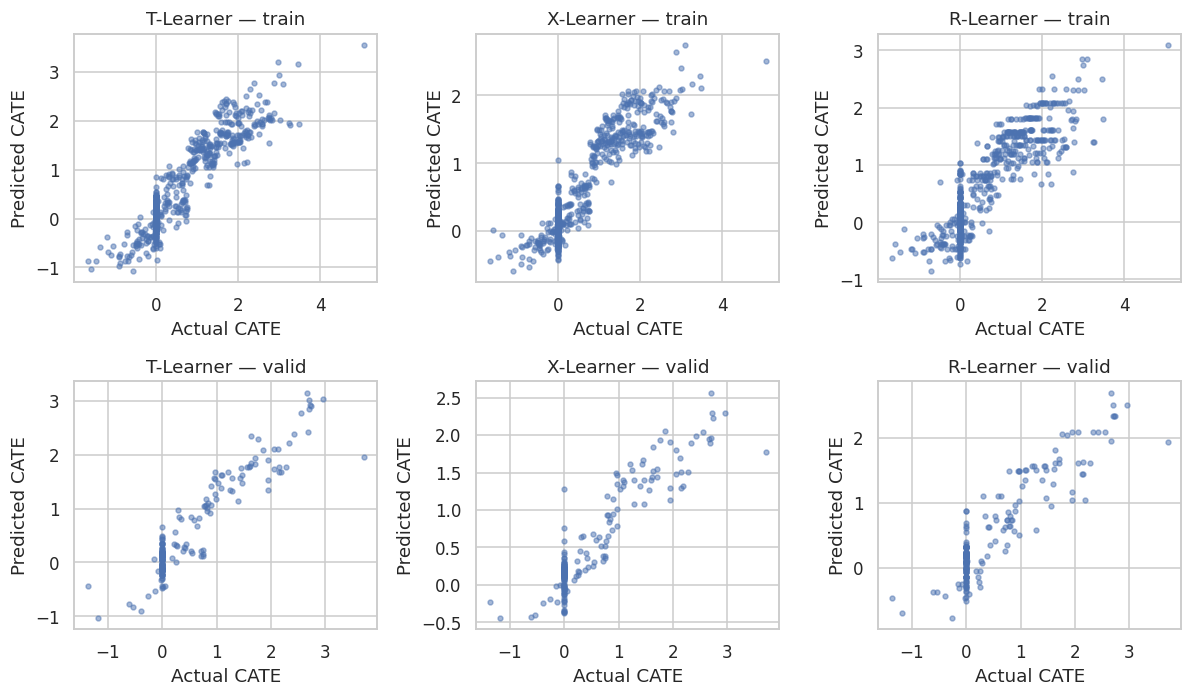

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for col, family in enumerate(single):
    for row, (split, truth_key) in enumerate((("train", "tau_train"), ("valid", "tau_valid"))):
        ax = axes[row, col]
        ax.scatter(single[family][truth_key], single[family][split], s=10, alpha=0.5)
        ax.set_title(f"{family} — {split}")
        ax.set_xlabel("Actual CATE")
        ax.set_ylabel("Predicted CATE")
fig.tight_layout()
plt.show()


### Cumulative Gain AUUC (like get_synthetic_auuc)

Area under the cumulative gain curve (same as Qini score in our package).


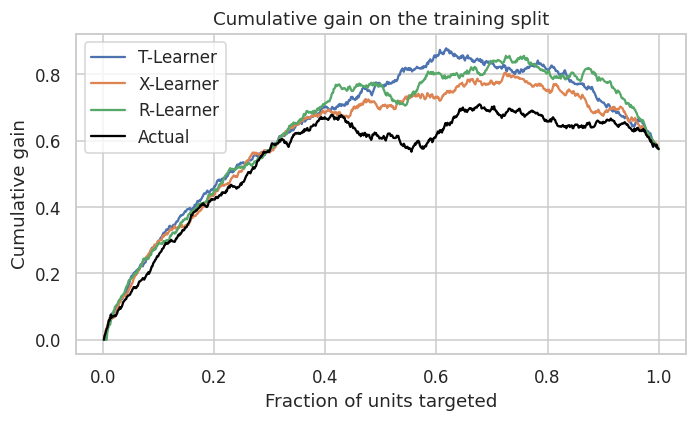

  learner  auuc
T-Learner 0.637
X-Learner 0.603
R-Learner 0.635
   Actual 0.548


In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4))
auuc_rows = []
for family, payload in single.items():
    frac, gain = cumulative_gain(payload["y_train"], payload["w_train"], payload["train"])
    ax.plot(frac, gain, label=family)
    auuc_rows.append({"learner": family, "auuc": float(np.trapezoid(gain, frac))})
frac, gain = cumulative_gain(payload["y_train"], payload["w_train"], payload["tau_train"])
ax.plot(frac, gain, color="black", label="Actual")
auuc_rows.append({"learner": "Actual", "auuc": float(np.trapezoid(gain, frac))})
ax.set_xlabel("Fraction of units targeted")
ax.set_ylabel("Cumulative gain")
ax.set_title("Cumulative gain on the training split")
ax.legend()
fig.tight_layout()
plt.show()
print(pd.DataFrame(auuc_rows).round(3).to_string(index=False))


## Part C: SHAP and interpretability



We take one **XGBoost** base learner per meta-learner family (S, T, X, R) for clearer nonlinear feature effects; the same workflow applies to `lm` or `learner="rf"` fits.


In [12]:
shap_models = {
    "S-Learner": fitted["S-Learner (XGBoost)"],
    "T-Learner": fitted["T-Learner (XGBoost)"],
    "X-Learner": fitted["X-Learner (XGBoost)"],
    "R-Learner": fitted["R-Learner (XGBoost)"],
}
explanations = {}
for name, model in shap_models.items():
    explanations[name] = explain_cate(model, X, max_samples=24, n_permutations=6, random_state=1)
    print(name, "mean |SHAP|", np.round(explanations[name].importance(), 3))


S-Learner mean |SHAP| [0.145 0.084 0.    0.    0.    0.    0.    0.    0.    0.   ]
T-Learner mean |SHAP| [0.41  0.292 0.009 0.003 0.019 0.    0.015 0.005 0.002 0.002]
X-Learner mean |SHAP| [0.239 0.294 0.045 0.008 0.015 0.005 0.026 0.004 0.005 0.008]
R-Learner mean |SHAP| [0.26  0.275 0.03  0.003 0.    0.006 0.02  0.004 0.018 0.028]


### Beeswarm and waterfall plots for one meta-learner (T-Learner with XGBoost base)


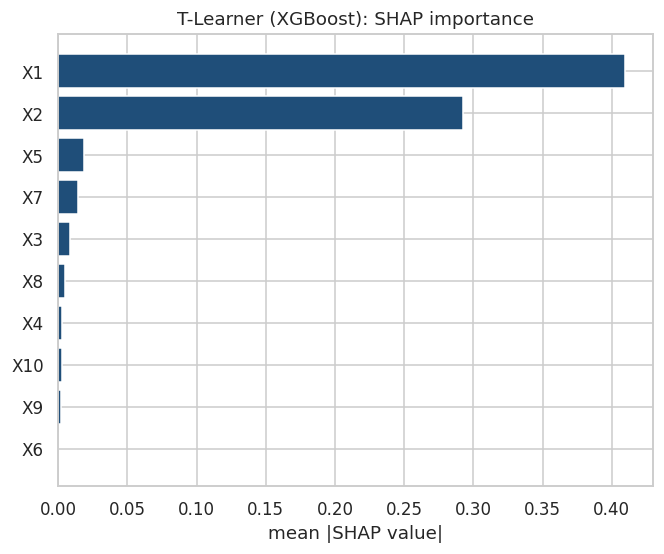

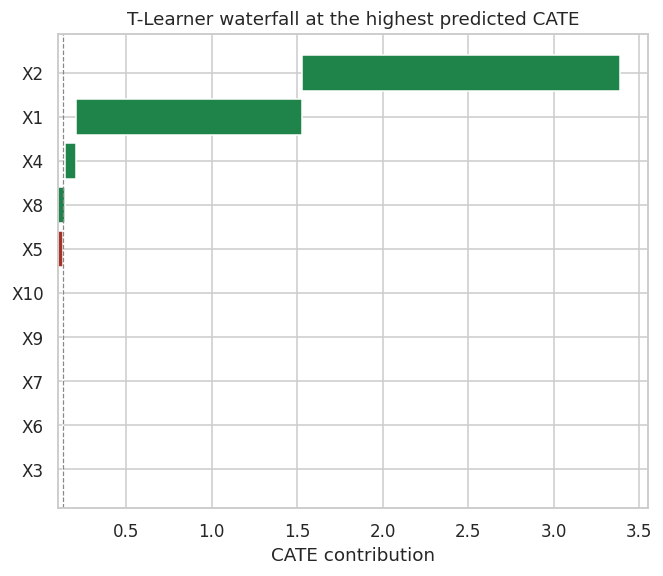

In [13]:
exp = explanations["T-Learner"]
exp.plot_importance(title="T-Learner (XGBoost): SHAP importance")
plt.show()
exp.plot_waterfall(row=int(np.argmax(exp.predictions)), title="T-Learner waterfall at the highest predicted CATE")
plt.show()


## Part D: Use case — abortion data

We apply the same meta-learner API to the **abortion** dataset from ``causaldata`` (state–year units; outcome **lnr**, logged gonorrhea rate among 15–19 year olds; treatment is **early repeal** of abortion prohibition). We load the raw table with `load_causaldata("abortion")$data`, restrict to ages 15–19, and encode treatment as a **binary factor** with levels `"Control"` (no early repeal) and `"Treated"` (early repeal). Internally, **PyCausalML** maps that factor to numeric codes (1 = Control, 2 = Treated with `levels = c("Control", "Treated")`), so every meta-learner below is constructed with `control_name = 1L`.

### Data


### Data Preparation


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

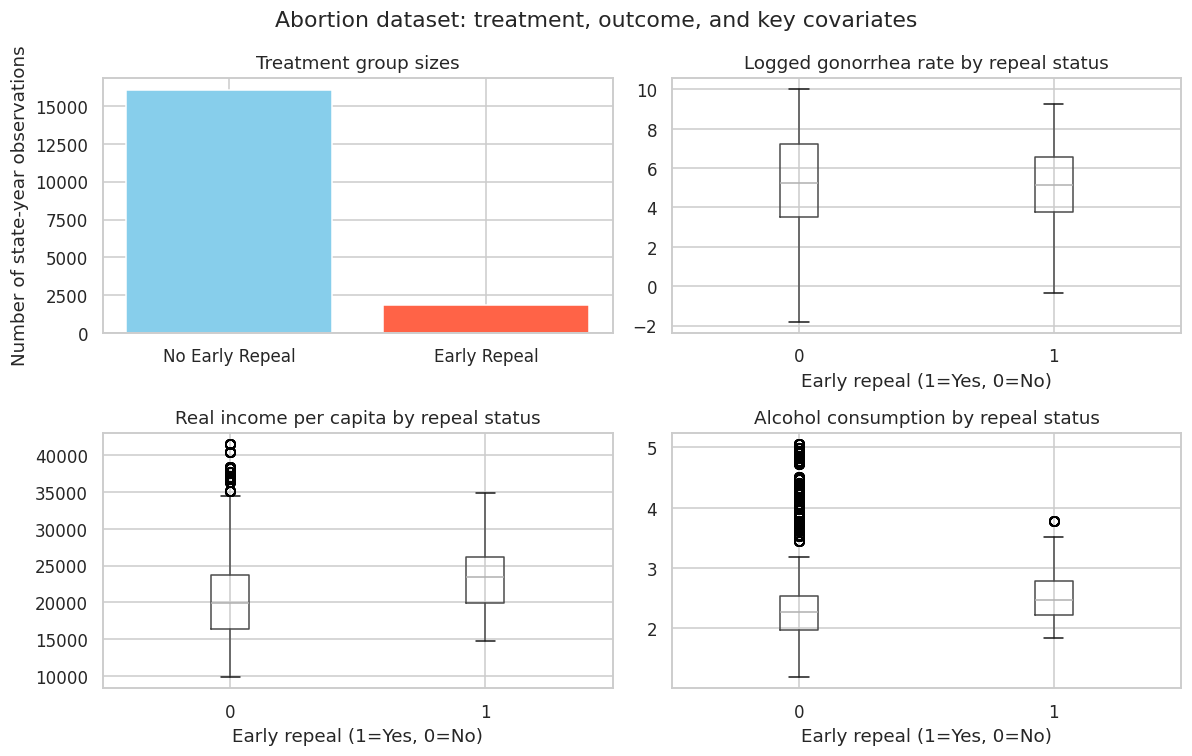

Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 17921  treated = 1854
Training set size: 14337
Test set size: 3584


In [14]:
from causaldata import abortion

abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_df = abortion_df.dropna(subset=["lnr"]).copy()
counts = plot_df["repeal"].value_counts().sort_index()
axes[0, 0].bar(["No Early Repeal", "Early Repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("Number of state-year observations")
plot_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal status")
axes[0, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
plot_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal status")
axes[1, 0].set_xlabel("Early repeal (1=Yes, 0=No)")
plot_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal status")
axes[1, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
plt.suptitle("Abortion dataset: treatment, outcome, and key covariates")
fig.tight_layout()
plt.show()

feature_names = [
    c for c in plot_df.columns
    if c not in ("lnr", "repeal") and plot_df[c].notna().all()
]
X_ab = plot_df[feature_names].to_numpy(dtype=float)
Y_ab = plot_df["lnr"].to_numpy(dtype=float)
W_ab = plot_df["repeal"].to_numpy(dtype=int)
print("Covariates used:", feature_names)
print("n =", len(Y_ab), " treated =", int(W_ab.sum()))

rng_ab = np.random.default_rng(333)
n_ab = len(Y_ab)
train_idx = rng_ab.choice(n_ab, size=round(0.8 * n_ab), replace=False)
test_idx = np.setdiff1d(np.arange(n_ab), train_idx)
X_ab_tr, X_ab_te = X_ab[train_idx], X_ab[test_idx]
Y_ab_tr, Y_ab_te = Y_ab[train_idx], Y_ab[test_idx]
W_ab_tr, W_ab_te = W_ab[train_idx], W_ab[test_idx]
print("Training set size:", len(Y_ab_tr))
print("Test set size:", len(Y_ab_te))


### Data split


### Fit ATE meta-learners on training split and estimate ATE


In [15]:
ab_models = {}
ab_rows = []
for family, cls in families.items():
    model = cls(learner="rf", n_estimators=N_EST, random_state=333)
    model.fit(X_ab_tr, W_ab_tr, Y_ab_tr, feature_names=feature_names)
    ab_models[family] = model
    row = ate_row(family, model, X_ab_tr)
    row["mean_cate_test"] = float(np.mean(model.predict(X_ab_te)))
    ab_rows.append(row)
print(pd.DataFrame(ab_rows).round(3).to_string(index=False))


  learner    ate    se  ci_lower  ci_upper  mean_cate_test
S-Learner  0.000 0.000     0.000     0.000           0.000
T-Learner -0.187 0.006    -0.198    -0.176          -0.174
X-Learner -0.125 0.005    -0.136    -0.115          -0.127
R-Learner -0.387 0.090    -0.564    -0.211          -0.211


### Visualize predicted CATE distribution on training split


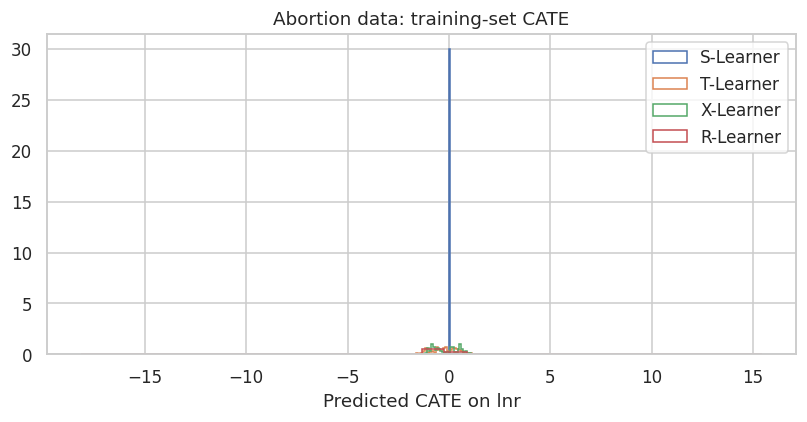

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for family, model in ab_models.items():
    ax.hist(model.predict(X_ab_tr), bins=30, histtype="step", density=True, label=family)
ax.set_xlabel("Predicted CATE on lnr")
ax.set_title("Abortion data: training-set CATE")
ax.legend()
fig.tight_layout()
plt.show()


### SHAP for predicted CATE (abortion, training subsample)


In [17]:
ab_explain = explain_cate(
    ab_models["T-Learner"], X_ab_tr, max_samples=24, n_permutations=6,
    feature_names=feature_names, random_state=333,
)
print("T-Learner mean |SHAP|")
print(pd.Series(ab_explain.importance(), index=ab_explain.feature_names).round(3).sort_values(ascending=False).to_string())


T-Learner mean |SHAP|
wht        0.322
age        0.249
income     0.142
sex        0.109
t          0.097
year       0.090
male       0.076
alcohol    0.062
totpop     0.051
race       0.047
poverty    0.040
ur         0.013
acc        0.001
fip        0.000
ir         0.000
crack      0.000
younger    0.000
pi         0.000
bf15       0.000


### Visualize SHAP with beeswarm and waterfall plots for one meta-learner (T-Learner with ranger base)


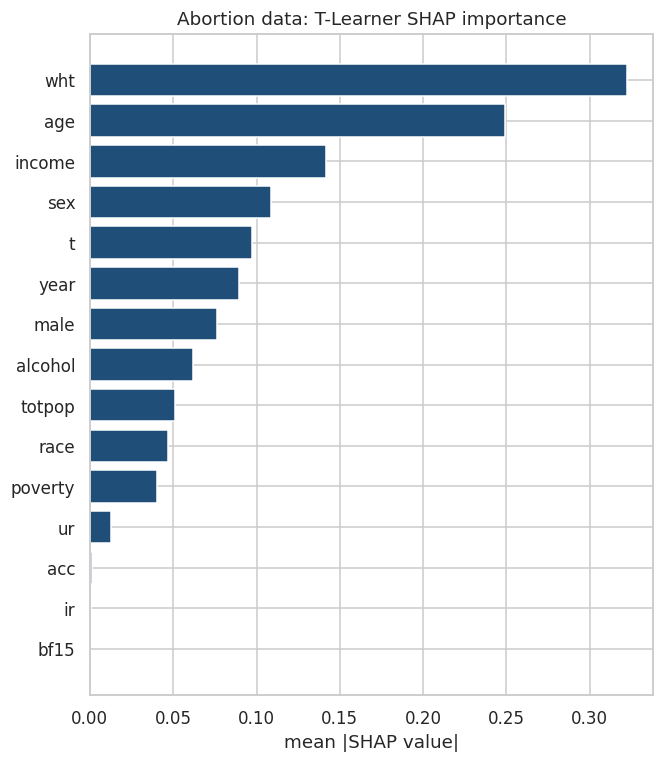

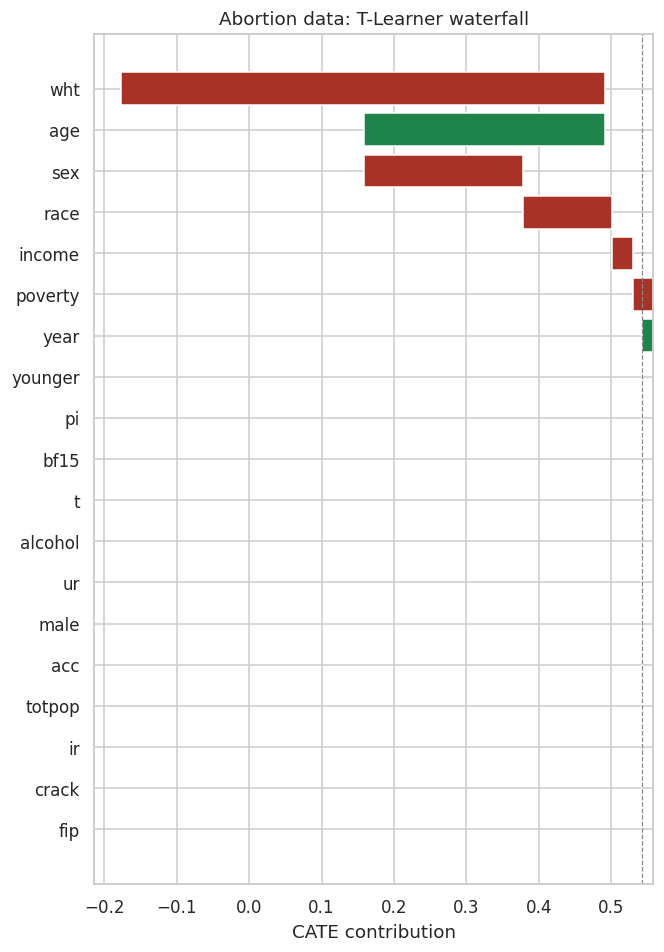

In [18]:
ab_explain.plot_importance(title="Abortion data: T-Learner SHAP importance")
plt.show()
ab_explain.plot_waterfall(row=0, title="Abortion data: T-Learner waterfall")
plt.show()


On observational data we do not observe true individual treatment effects, so Part B–style PEHE and AUUC benchmarks against simulated $\tau$ do not apply. The ATE table and histograms summarize **estimated** policy effects on **lnr** and the dispersion of **predicted** CATE across training units for each meta-learner. **SHAP** (above) describes which covariates move each meta-learner's $\hat{\tau}(X)$ on the explained training subsample.

## Summary and Conclusions

This notebook demonstrates how to use **PyCausalML** to implement meta-learners (S-, T-, X-, R-learners) for estimating heterogeneous treatment effects (CATE/ITE) on synthetic data. We validate the meta-learners' performance using train/validation splits and report metrics like Abs % Error of ATE, MSE, KL Divergence, and AUUC. The results show how different meta-learners and base regressors perform in estimating CATE, with visualizations of predicted vs actual CATE distributions and scatter plots. Part C uses **SHAP** (via `explain_cate()`, `permutation SHAP`, and `PyCausalML SHAP plots`) to summarize which covariates drive each meta-learner's predicted CATE on a held subset of units, optionally **in parallel** using **future** (`multisession`) and `parallel = TRUE` in `permshap`. **Part D** fits S-, T-, X-, and R-learners on the **abortion** dataset with treatment coded as `"Control"` / `"Treated"`, reports training-set ATE estimates and predicted-CATE histograms, and applies the same **SHAP** workflow to a training subsample for interpretability.

## References

-   [CausalML Meta-Learners with Synthetic Data](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data.html)
-   Nie & Wager (2018). Quasi-Oracle Estimation of Heterogeneous Treatment Effects.
-   Künzel et al. (2019). *PNAS*: Metalearners for HTE estimation
-   Athey & Wager (2019). *arXiv*: Generalized random forests (causal_forest)
-   Chernozhukov et al. (2018). *Econometrica*: Double/debiased ML (DoubleML)
